# 07 — Figure guide: every scJDO2 figure, how to make it, how to read it

This notebook renders **every figure in `scjdo2.plot`** on real stored runs
(or, where the truth is needed, on a synthetic system with a known answer) and
explains, for each one:

* **Question** — what the figure is for;
* **Needs** — which analysis has to run first;
* **How to read it** — panel by panel;
* **Watch out** — the common misreadings.

| Part | Figures | Data |
|---|---|---|
| A. Operator space | `figure_operator_space`, `figure_archetype_sheet`, `plot_drivers`, `figure_ledger_summary`, `figure_v1_vs_v2` | Paul15 v2 run (gene-space Jacobian, archetypes) |
| B. Symmetric (snapshot) operator | `figure_spectrum_ladder`, `figure_soft_axis_map`, `figure_ledger_map`, `figure_basin_index`, `figure_oracle_agreement` | PBMC 3k and pitchfork, v0.5 lock |
| C. Landscapes and motifs | `figure_behaviour_ternary`, `figure_behaviour_landscape`, `figure_behaviour_landscape_3d`, `figure_energy_landscape`, `figure_motif_matrix` | synthetic pitchfork (analytic truth known) |
| D. Perturbation | `figure_perturb_paired` | K562 Perturb-seq tables |
| E. Aging | `figure_aging_vectors`, `figure_energy_transect` | aging comparison tables |
| F. Drivers and timing | `figure_influence_network`, `figure_reference_auroc`, `figure_expression_cascade`, `figure_branch_timing`, `figure_network_expression` | Paul15 v2 run + TRRUST |

### Conventions shared by every figure

* Every `figure_*` function **returns a matplotlib `Figure`** and takes
  **`out=`** — a path *stem*; it writes `out.pdf` and `out.png`
  (`scjdo2.plot.save_figure`). `out=None` writes nothing.
* Figure functions **only draw**. They read results stored on the AnnData
  (or a result dict you pass) and raise a clear error if the analysis has not
  run. The one-call APIs `scjdo2.landscape` and `scjdo2.drivers` run the
  analyses and have `figures()` helpers that render everything at once.
* Eigenvalue and time axes say **"(relative)"** unless the run's clock is
  calibrated (`uns["scjdo2"]["clock_calibrated"]`): the operator's time unit
  is arbitrary, so only signs and ratios are comparable across datasets.
* Behaviour colours are shared everywhere: **holder** (basin) blue, **fork**
  orange-red, **drift** grey, oscillators purple (ringed marker). Driver-role
  colours: **driver** amber, **hub** purple, **responder** green,
  **passenger** grey, **unmeasured** white with a dashed outline.

In [1]:
import time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import anndata as ad
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Image, display

import scjdo2
import scjdo2.plot as P
from scjdo2 import io, opspace, landscape, motifs
from scjdo2 import drivers as D

warnings.filterwarnings("ignore")
REPO = Path("..").resolve()
OUT = REPO / "benchmarks" / "v2" / "tutorial_07"
OUT.mkdir(parents=True, exist_ok=True)
SEED = 0


def show(fig, width=None):
    # Display a returned Figure inline and free it.
    display(fig)
    plt.close(fig)


T0 = time.time()
print("figures in scjdo2.plot:", sorted(n for n in P.__all__ if n.startswith(("figure_", "plot_"))))

figures in scjdo2.plot: ['figure_aging_vectors', 'figure_archetype_sheet', 'figure_basin_index', 'figure_behaviour_landscape', 'figure_behaviour_landscape_3d', 'figure_behaviour_ternary', 'figure_branch_timing', 'figure_energy_landscape', 'figure_energy_transect', 'figure_expression_cascade', 'figure_influence_network', 'figure_ledger_map', 'figure_ledger_summary', 'figure_motif_matrix', 'figure_network_expression', 'figure_operator_space', 'figure_oracle_agreement', 'figure_perturb_paired', 'figure_reference_auroc', 'figure_soft_axis_map', 'figure_spectrum_ladder', 'figure_v1_vs_v2', 'plot_drivers']


---
## Part A — Operator space (Paul15 v2 run)

The Paul15 run (mouse myeloid progenitors, 2,730 cells, 301 genes) has the full
v2 state: a latent drift, per-cell latent Jacobians `J_c`, a gene-space Jacobian
from the NB rate model with its Fisher ledger, and semi-NMF archetype weights.
`archetype_operators` rebuilds the per-archetype operators (it also stores the
operator block and projector the driver figures in Part F need).

In [2]:
t = time.time()
paul = io.load(REPO / "benchmarks" / "v2" / "paul15")
opspace.archetype_operators(paul)
arch = paul.uns["scjdo2"]["archetypes"]
print(paul, f"\n{len(arch)} archetypes; loaded + operators in {time.time() - t:.0f}s")
pd.DataFrame({k: {"behaviour": v["behaviour"], "n_cells": v["n_cells"],
                  "lead_re": float(np.real(v["eigenvalues"][0])),
                  "henrici": v["henrici"]} for k, v in arch.items()}).T

AnnData object with n_obs × n_vars = 2730 × 301
    obs: 'paul15_clusters', 'dpt_pseudotime', 'pseudotime', 'lead_re', 'lead_im', 'n_stable', 'n_unstable', 'n_near_zero', 'n_complex_pairs', 'spectral_gap', 'henrici', 'transient_gain', 'reactivity', 'eigvec_cond', 'op_confidence', 'op_behaviour', 'op_sensitive', 'op_rank', 'op_field_gradient'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'diffmap_evals', 'hvg', 'iroot', 'log1p', 'neighbors', 'pca', 'scjdo', 'scjdo2', 'scjdo_prep', 'umap'
    obsm: 'X_diffmap', 'X_drift', 'X_drift_v', 'X_latent', 'X_pca', 'X_umap', 'X_velocity_pseudo', 'archetype_weights', 'op_eigvals'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances' 
8 archetypes; loaded + operators in 34s


,behaviour,n_cells,lead_re,henrici
0,fork,411,0.694011,0.346101
1,fork,323,0.525568,0.226679
2,fork,601,0.272644,0.352477
3,fork,702,0.292399,0.197632
4,fork,506,0.407716,0.306098
5,fork,561,0.503913,0.335689
6,fork,949,0.098287,0.190128
7,fork,372,0.466752,0.481852


### A1. `figure_operator_space` — the overview

**Question.** Where on the embedding is each behaviour, what do the cells'
leading eigenvalues look like, and which genes carry the leading mode?

**Needs.** `opspace.spectrum`, `invariants`, `behaviour` (stored in `obs`:
`lead_re`, `lead_im`, `op_behaviour`, `op_confidence`); for Panel C a
gene-space Jacobian, ideally archetype operators.

**How to read it.**
* **Panel A — embedding** coloured by the leading real eigenvalue
  `lead_re` on a diverging scale centred at 0: blue = contracting (holder /
  basin), red = expanding (fork). Transparency = operator confidence (Fisher),
  so faint cells are poorly measured. Dashed rings mark *sensitive* cells
  (strongly non-normal operators, Henrici above threshold).
* **Panel B — complex plane** (`measured_flow=True`): each cell at
  (`Re λ₁`, `Im λ₁`), coloured by behaviour. Cells on the real axis are
  holders (left) or forks (right); cells off the axis rotate (oscillators).
  For a symmetric snapshot operator (`measured_flow=False`, the default) this
  panel is replaced by a ladder of `lead_re`, because every `Im λ` is 0.
* **Panel C — gene bars** for one archetype's leading mode (default: the
  first fork archetype): signed weight of each gene in the mode (right = up
  together, left = down together). Whiskers are ± one Fisher standard error;
  bar shade follows Fisher confidence. Hollow bars are genes whose entries
  were not measured (reason code at the bar end). A whisker that crosses zero
  means the sign of that gene's weight is not resolved.

**Watch out.** `lead_re` is in relative time units. Panel C shows the
*right* eigenvector, i.e. the genes that **move** along the mode
(responders) — not the genes that cause the movement; Part F does that.

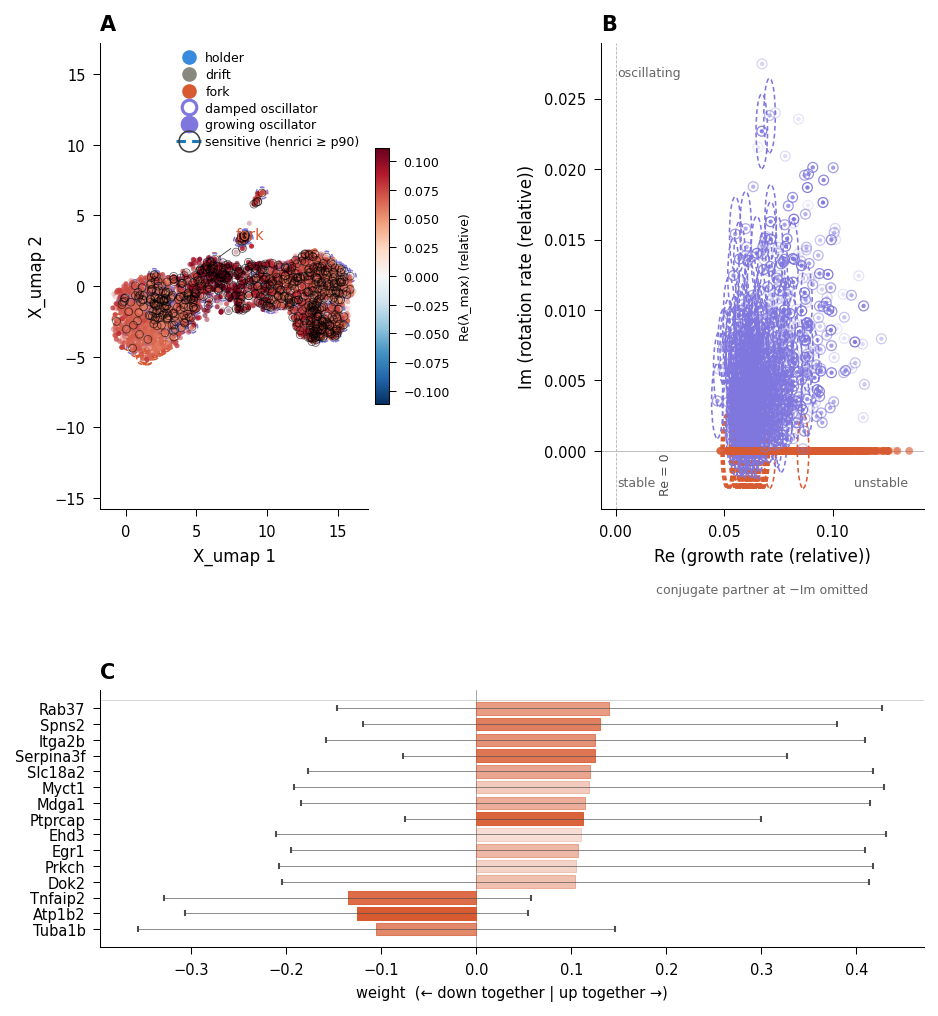

In [3]:
fig = P.figure_operator_space(paul, measured_flow=True, out=OUT / "A1_operator_space")
show(fig)

### A2. `figure_archetype_sheet` — one row per archetype

**Question.** What are the recurring operator types (archetypes), and how do
they differ in spectrum and genes?

**Needs.** `opspace.archetype_operators`.

**How to read it.** Each row is one archetype (sorted by behaviour, then size):
* **left inset** — the archetype operator's eigenvalues in the complex plane;
  the rightmost one sets the behaviour (fork if `Re > tol`);
* **middle** — the top genes of its leading mode (as in Panel C);
* **right** — a stats block: behaviour, number of member cells, lead
  eigenvalue, Henrici (non-normality), transient gain, median confidence.

**Watch out.** Archetypes are a *decomposition* of per-cell operators
(`J_c ≈ Σ_k W[c,k] H_k`), not clusters of cells; a cell can belong to
several. Member cells here are those with weight ≥ half the archetype's
maximum.

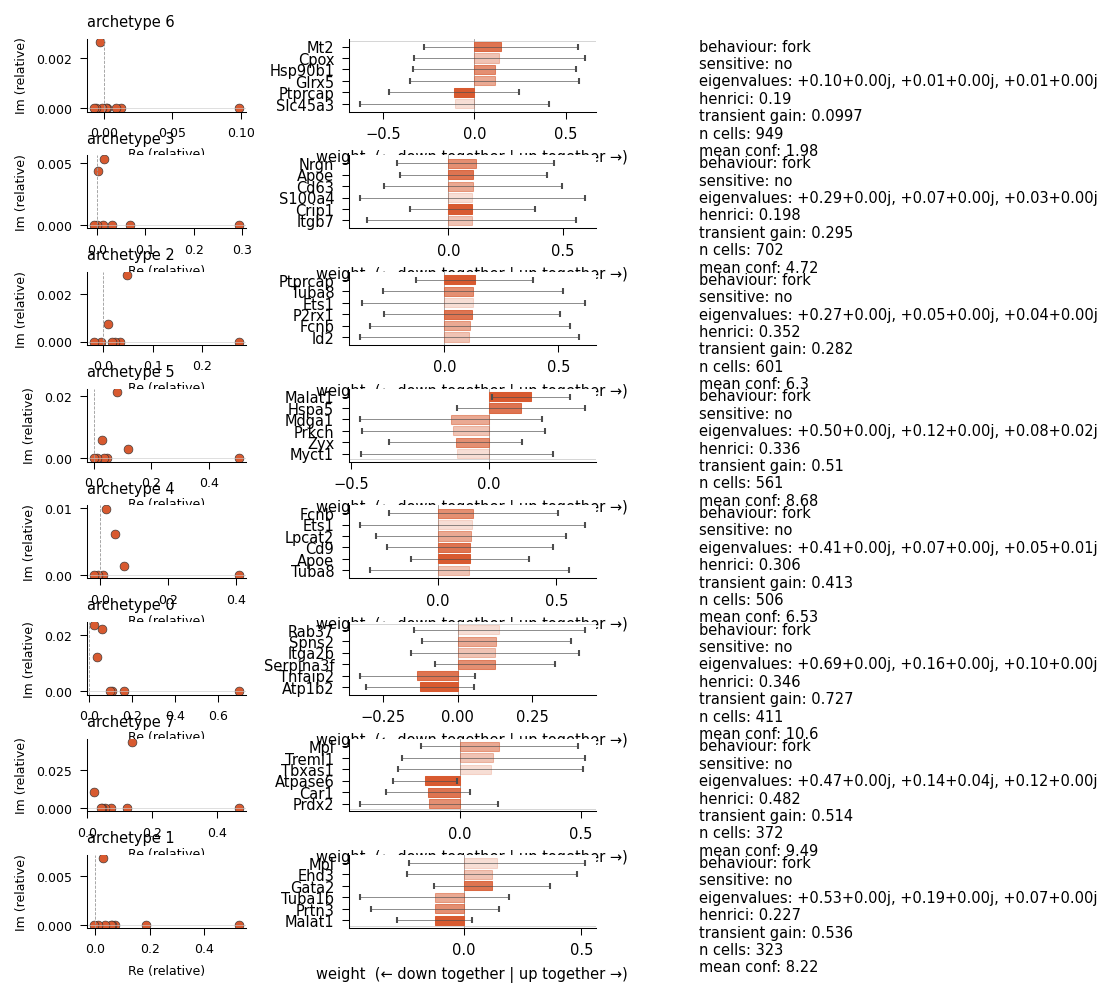

In [4]:
fig = P.figure_archetype_sheet(paul, top=6, out=OUT / "A2_archetype_sheet")
show(fig)

### A3. `plot_drivers` — the axis-level driver bars (responders vs drivers)

`plot_drivers(ax, table)` draws into an axis you provide, so you can compose
panels. Here it shows the difference between the two eigenvector readings for
the same archetype:

* **responders** (`kind="responders"`, right eigenvector) — genes that change
  most along the mode;
* **drivers** (`kind="drivers"`, left eigenvector, sensitivity
  `∂λ/∂J`) — genes whose rows of `J` control the eigenvalue.

**How to read it.** Bars are signed weights (real mode) or magnitudes coloured
by phase (complex mode, cyclic colour map). Hollow bars = unmeasured genes
(capped / no variation), tagged with the reason. If the two lists are similar,
the operator is close to normal and "what moves" ≈ "what controls".

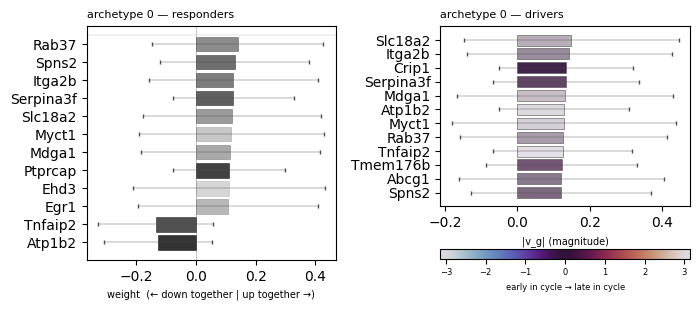

In [5]:
k = next(a for a, v in arch.items() if v["behaviour"] == "fork")
fig, axes = plt.subplots(1, 2, figsize=(7.1, 3.2))
for ax, kind in zip(axes, ("responders", "drivers")):
    tbl = opspace.drivers(paul, which="archetype", archetype_id=k, kind=kind, top=12)
    P.plot_drivers(ax, tbl, top=12)
    ax.set_title(f"archetype {k} — {kind}", fontsize=8, loc="left")
fig.tight_layout()
P.save_figure(fig, OUT / "A3_plot_drivers")
show(fig)

### A4. `figure_ledger_summary` — how much of the Jacobian is measured

**Question.** How trustworthy are the gene-space Jacobian entries?

**Needs.** The Phase C Fisher ledger (`uns["scjdo2"]["fisher_ledger"]`).

**How to read it.**
* **left** — for each decile of operator confidence, the share of gene
  entries with each reason code: `ok` (measured), `no_variation` (the gene
  does not vary in the cell's neighbourhood), `capped` (dropped by the
  per-anchor storage cap), `not_in_ball`, `no_counts`. A good run has `ok`
  growing with confidence.
* **right** — histogram of the per-cell tangent rank: how many directions the
  local neighbourhood actually spans. Eigen-analysis is only meaningful inside
  this tangent.

**On this run** the panel is flat: Paul15 was fitted per cell with no storage
cap, so every stored entry is `ok` and `op_confidence` is the same for every
cell (the figure then shows one pooled bar). On anchor-cap runs (e.g. Setty)
the deciles separate and `capped` / `no_variation` appear at low confidence.

**Watch out.** A gene with zero Fisher is *not measured*, not *unimportant*.
Every downstream driver call treats it that way (Part F marks it unmeasured).

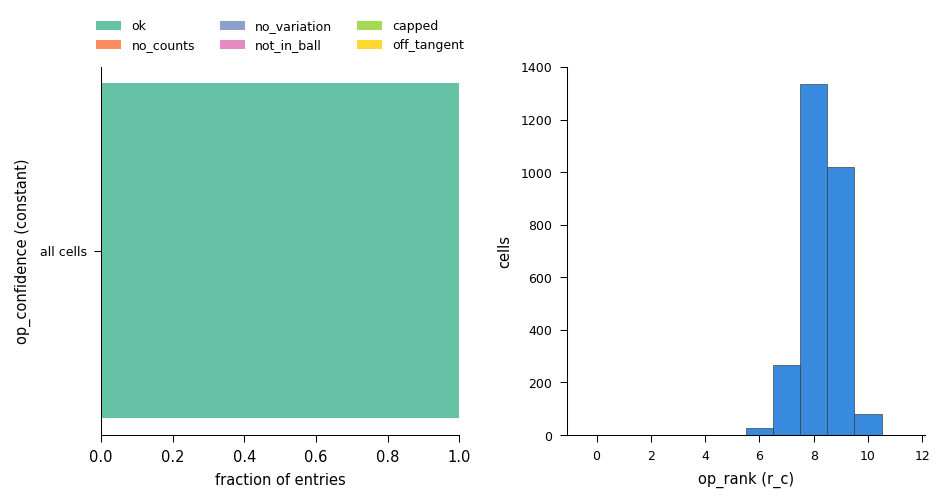

In [6]:
fig = P.figure_ledger_summary(paul, out=OUT / "A4_ledger_summary")
show(fig)

### A5. `figure_v1_vs_v2` — what changed from scJDO v1

**Question.** How does v1's pseudotime-window view compare with v2's per-cell
operator view on the same cells?

**Needs.** A v1 baseline directory (`compare/run_v1.py` output with
`uns["scjdo"]["activations"]`, `["t_centers"]`) and the v2 AnnData.

**How to read it.** Left: v1 — archetype activations along pseudotime windows
(one curve per v1 archetype). Right: v2 Panel A on the same embedding. v1 can
only say *when* (which window) an archetype is active; v2 says *which cells*
and *what kind* of operator.

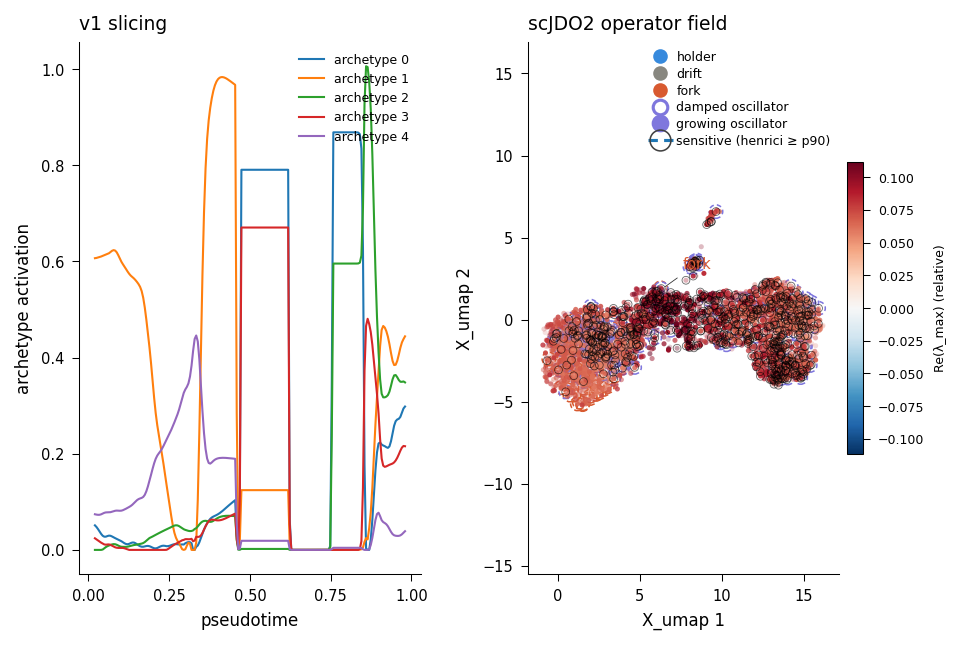

In [7]:
fig = P.figure_v1_vs_v2(paul, v1_results=REPO / "benchmarks" / "v1_baseline" / "paul15",
                        out=OUT / "A5_v1_vs_v2")
show(fig)

---
## Part B — The symmetric (snapshot) operator: basins and saddles

On snapshot data with no measured velocity, the v0.5 path learns a score drift
whose Jacobian is **symmetric**: `J = −∇²E`, the curvature of the learned log
density. Its eigenvalues are real, so the reading is *landscape* only:

* all eigenvalues negative → a **basin** (cells are held; `op_behaviour_basin = holder`);
* one positive → a **saddle** (`fork`): a density ridge between basins;
* `|λ| < tol` → a **soft** direction (flat; cells can drift).

`op_basin_index = −lead_re`: large = deep basin. These figures use the locked
v0.5 runs on PBMC 3k (real) and on the equilibrated pitchfork (synthetic,
where the analytic Jacobian is known).

In [8]:
pbmc = ad.read_h5ad(REPO / "benchmarks" / "v0.5_lock" / "pbmc_v05.h5ad")
pitch = ad.read_h5ad(REPO / "benchmarks" / "v0.5_lock" / "pitchfork_v05.h5ad")
from scjdo2.data import RESTING_TYPES
print(pbmc.shape, pitch.shape, "resting types:", RESTING_TYPES)
pbmc.obs["op_behaviour_basin"].value_counts()

(2638, 3065) (1200, 200) resting types: ('CD4 T cells', 'CD8 T cells', 'B cells', 'CD14+ Monocytes')


op_behaviour_basin
fork      1239
holder    1185
drift      214
             0
Name: count, dtype: int64

### B1. `figure_spectrum_ladder` — the full spectrum per cell type

**Question.** For each cell type, how many directions hold the cells, how many
are soft, and does the learned curvature match a simple Gaussian?

**Needs.** Per-cell latent `J` (`uns["scjdo2"]["J"]`), clusters in `obs`.

**How to read it.** One vertical ladder per cluster: the eigenvalues of the
average `J` over the 30 cells nearest the cluster centroid.
* **Dashes = learned eigenvalues**, blue if all are below `+tol` (a basin),
  red if the top one is above it (a saddle direction exists).
* **Hollow circles = Gaussian oracle** (`−Σ⁻¹` of the cluster's latent
  covariance): the curvature a single Gaussian blob would have. It needs at
  least twice as many cells as latent dimensions; smaller types show
  "oracle n/a".
* The thin grey band around 0 is the soft zone (`|λ| < tol`).
* Under each ladder: `n_soft` (directions inside the soft zone) and `r`, the
  median learned/oracle ratio of the contracting eigenvalues (`r < 1`: the
  learned basin is shallower than a Gaussian of the same spread).

**Watch out.** A ladder entirely below zero means a basin *in the learned
density*, not proof of a stable dynamical state. Learned ≈ oracle means the
type looks like one Gaussian blob; large departures mean extra structure.

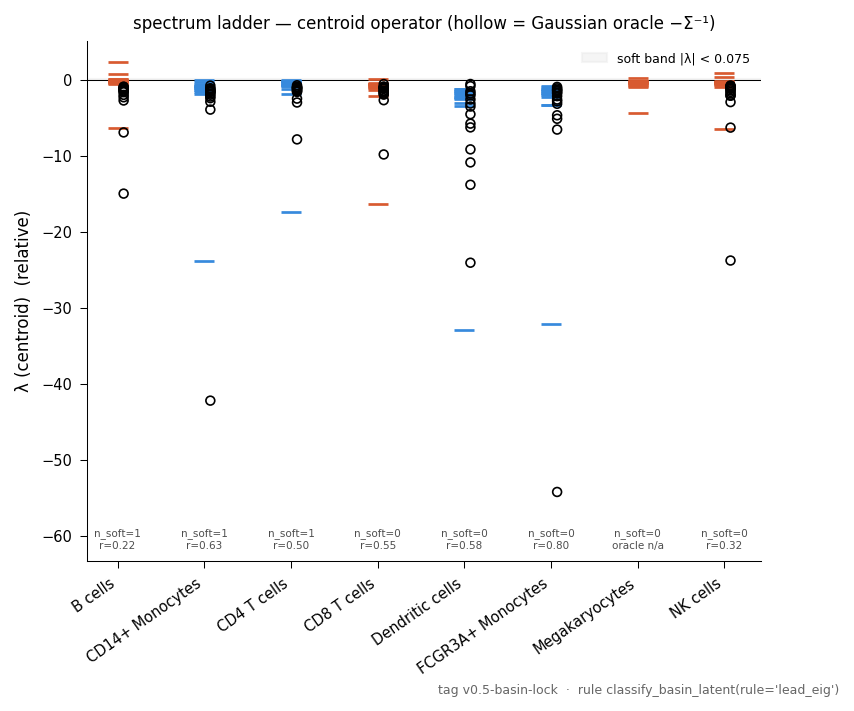

In [9]:
show(P.figure_spectrum_ladder(pbmc, by="cluster", out=OUT / "B1_spectrum_ladder"))

### B2. `figure_soft_axis_map` — the softest direction of each type

**Question.** Along which direction is each cell type least held (where would
cells most easily move)?

**How to read it.** Each label reads "type → nearest type" (the closest other
type's centroid, for orientation). Cells on the embedding, coloured by `basin_index`
(red = deep basin, blue = saddle). At each cluster centroid a black arrow
points along the centroid operator's **softest eigendirection** (largest
eigenvalue, i.e. the least-held axis), mapped onto the embedding by a local
linear fit. All arrows are drawn at the **same length**: only the direction
carries information. With `groups` and `displacement_arrow=True` (aging data)
a rust arrow shows the stored old-minus-young centroid displacement, so you
can see whether aging moves a type along its soft axis.

**Watch out.** An eigenvector's sign is arbitrary, so read the arrow as an
axis, not a direction of travel; the 2-D projection can also shorten or
rotate a direction that mostly leaves the embedding plane.

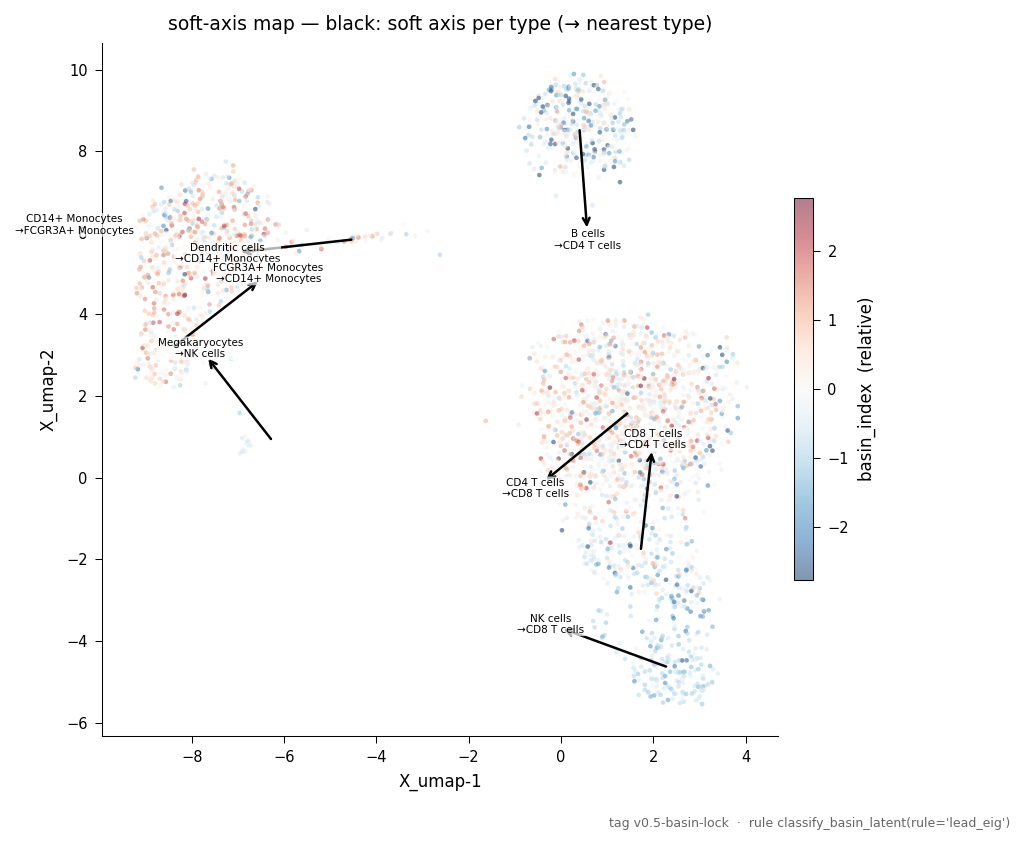

In [10]:
show(P.figure_soft_axis_map(pbmc, by="cluster", out=OUT / "B2_soft_axis_map"))

### B3. `figure_ledger_map` — the provenance of each cell's label

**Question.** Which cells were called basin, saddle or drift, and which could
not be determined?

**How to read it.** The embedding coloured by class: **basin** (holder),
**saddle** (fork, a density ridge), **drift** (`|lead_re| < tol`) and
**not determinable** (no valid operator). The legend gives counts.

**Watch out.** "Saddle" here means a ridge of the learned density, which often
— but not always — coincides with a transition between types.

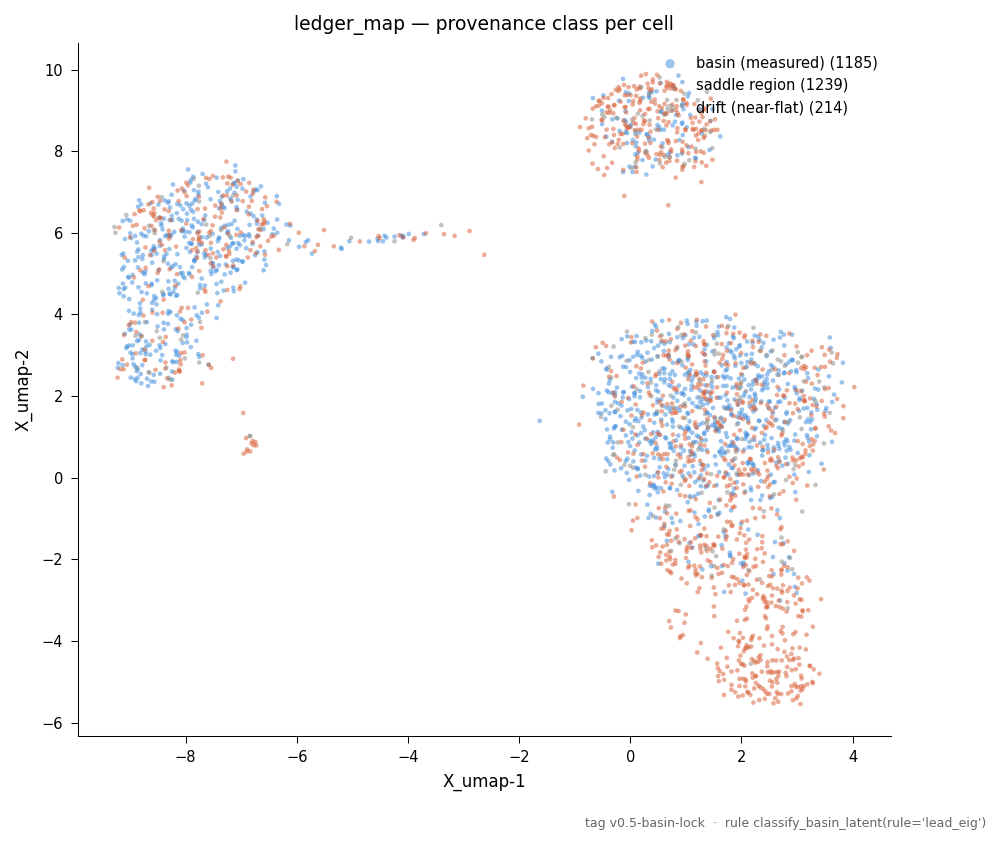

In [11]:
show(P.figure_ledger_map(pbmc, out=OUT / "B3_ledger_map"))

### B4. `figure_basin_index` — basin depth by cell type

**Question.** Which types sit in deep basins, and do mature resting types do
so more than cycling or activated ones?

**How to read it.** Two panels sharing the x-axis, types ordered by median
`basin_index` (`−lead_re`, deepest first):
* **top** — one jittered strip of cells per type with the median as a black
  bar; the dashed line is 0 (above = held, below = saddle);
* **bottom** — the fraction of each type called holder (basin) by the locked
  rule; the dashed line is the pooled basin fraction over the declared
  resting types.

Resting types (`resting_types=`) are drawn in blue, the others grey.

**Watch out.** Depth is curvature of the log density: abundant, tight types
look deep. Compare types within a dataset, not across datasets.

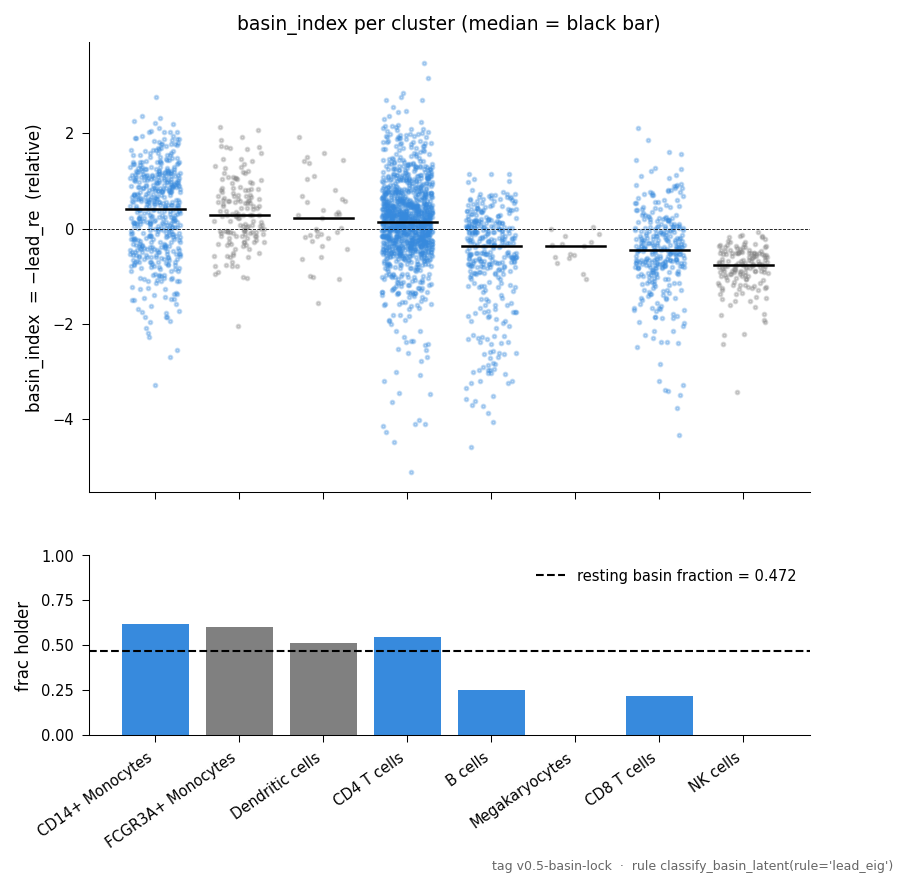

In [12]:
show(P.figure_basin_index(pbmc, by="cluster", resting_types=RESTING_TYPES,
                          out=OUT / "B4_basin_index"))

### B5. `figure_oracle_agreement` — does the learned operator match the truth?

**Question.** On a system where the true Jacobian is known, does the learned
leading eigenvalue track it?

**Needs.** The equilibrated pitchfork (analytic Jacobian), `tau_crit` = the
bifurcation point.

**How to read it.** Each cell at (analytic `lead_re`, learned `lead_re`); the
shaded region is the true holder side (analytic `lead_re < 0`), the dashed
lines are the two zeros. **Red points are the cells nearest the bifurcation**
(pseudotime within `window` of `tau_crit`), where the true operator changes
sign. The box gives the Spearman correlation and the AUC for telling those
saddle cells from holders by the learned value. A good operator puts the grey
cloud in the lower-left quadrant (learned and true both negative) and the red
points to the right of it.

**Watch out.** Read the AUC and the quadrant pattern, not the diagonal: the
learned value is a density curvature in relative units, so its scale need not
match the analytic one. On this run agreement is moderate (Spearman ≈ 0.5):
the density Hessian equals the dynamics Jacobian only near stable states,
which is why the holder cells (far left) agree best.

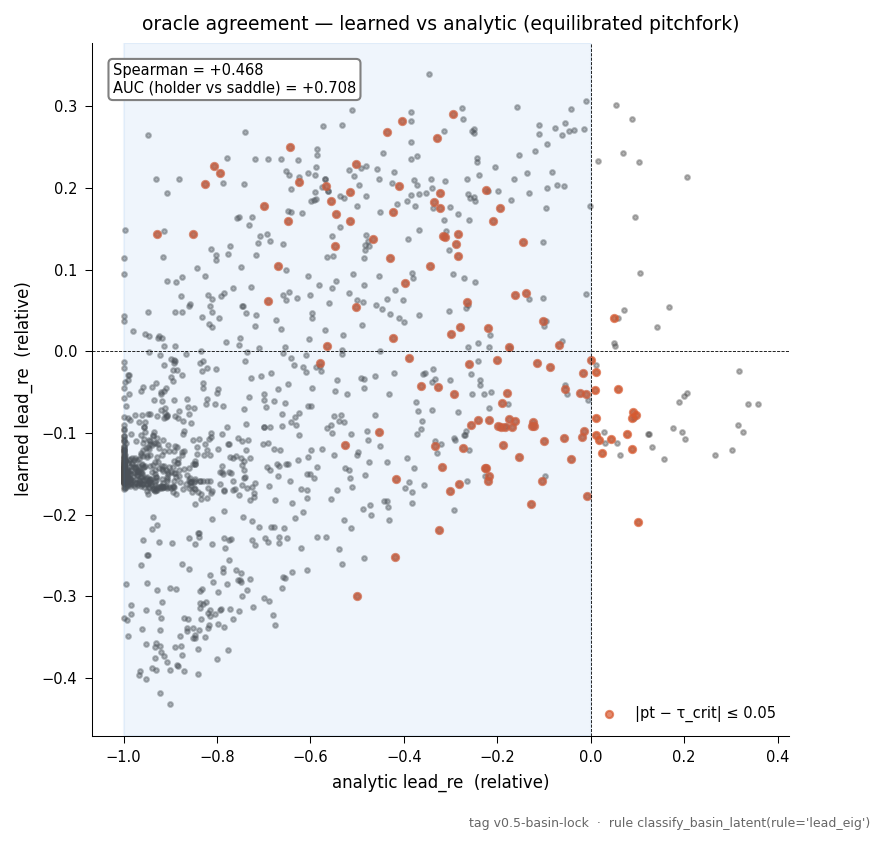

In [13]:
tau = float(pitch.uns.get("v05_meta", {}).get("tau_crit", 0.3))
show(P.figure_oracle_agreement(pitch, tau_crit=tau, out=OUT / "B5_oracle_agreement"))

For comparison, `figure_operator_space` on a snapshot run uses the
**snapshot routing** (`measured_flow=False`): Panel A coloured by
`basin_index` (red = deep basin, blue = saddle), and Panel B a strip of every
cell's `lead_re` (x is just cell order) instead of the complex plane, since a
symmetric operator has no imaginary parts. Panel C needs a gene-space
Jacobian; this PBMC run has only the latent one, so the panel states why it is
empty instead of drawing genes.

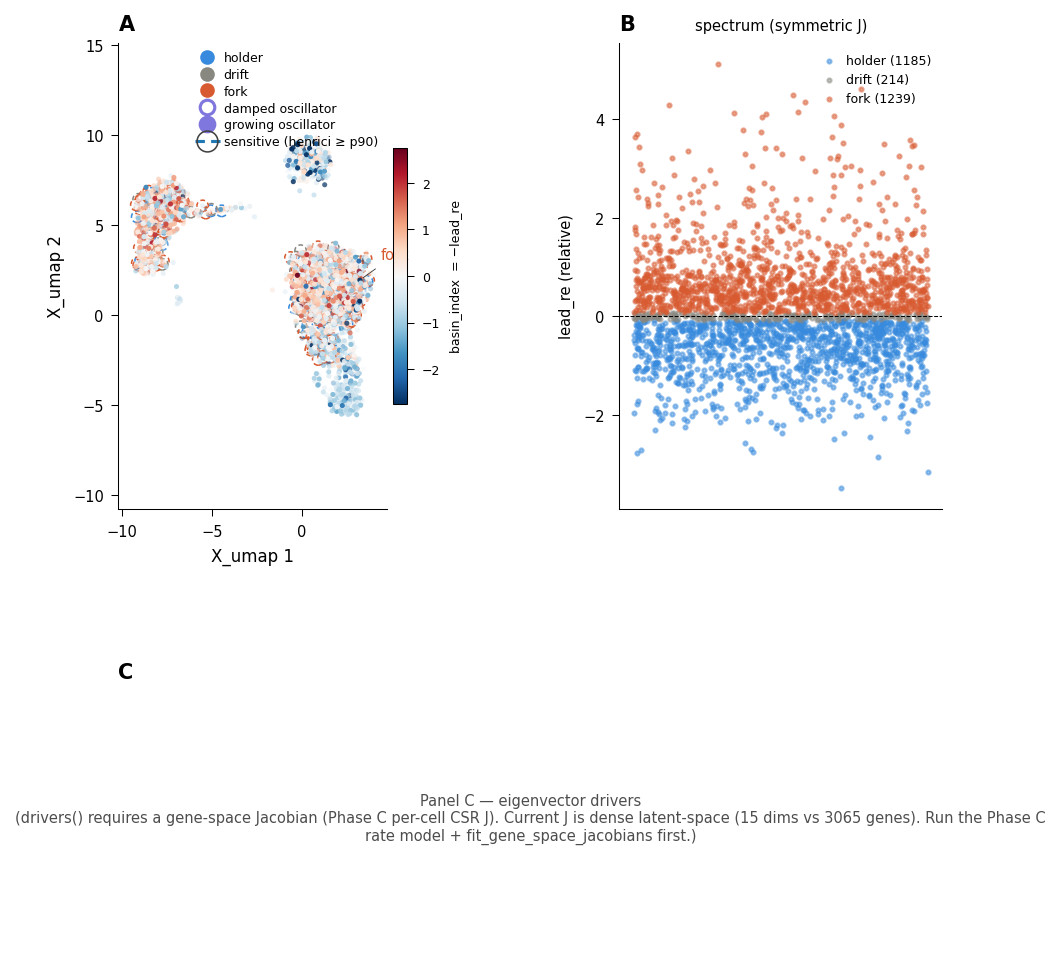

In [14]:
show(P.figure_operator_space(pbmc, by="basin_index", out=OUT / "B6_operator_space_snapshot"))

---
## Part C — Behaviour landscape, energy landscape and motifs

These figures summarise **where cells sit in operator space** rather than on
the embedding. They are made by `scjdo2.landscape` (tutorial 06 covers the
analysis in depth). We regenerate the equilibrated pitchfork, where the answer
is known, fit a short energy drift, and run `landscape.analyse`.

In [15]:
from scjdo2.data.synthetic_pitchfork import generate_pitchfork_equilibrated
from scjdo2.energy_drift import EnergyDriftAdapter, EnergyDriftConfig

pf = generate_pitchfork_equilibrated(tau_crit=0.3, n_cells=1200, n_genes=200, n_latent=20, seed=SEED)
Xt, pt = pf.obsm["X_true"], pf.obs["pseudotime"].to_numpy()
diff = Xt[:, 0] - Xt[:, 1]
pf.obs["cluster"] = pd.Categorical(np.where(np.abs(diff) < 0.35, "saddle", np.where(diff > 0, "upper", "lower")))
pf.obs["condition"] = pd.Categorical(np.where(pt < 0.5, "early", "late"))
pf.obs["donor"] = pd.Categorical(np.random.default_rng(SEED).choice(["d1", "d2", "d3"], size=pf.n_obs))
pf.uns["scjdo2"] = {"meta": {"use_rep": "X_pca", "clock_calibrated": False}}

z = np.asarray(pf.obsm["X_pca"], dtype=np.float32)
t = time.time()
drift = EnergyDriftAdapter(dim=z.shape[1], config=EnergyDriftConfig(
    n_epochs=800, hidden=96, depth=3, seed=SEED, device="cpu")).fit(z)
pf.uns["scjdo2"]["J"] = drift.jacobian_autodiff(z)
info = landscape.analyse(pf, cluster_key="cluster", resting_types=("upper", "lower"),
                         drift=drift, motifs=True, replicate_key="donor", n_perm=100, seed=SEED)


def fit_marginal(z_perm, seed):
    return EnergyDriftAdapter(dim=z_perm.shape[1], config=EnergyDriftConfig(
        n_epochs=300, hidden=96, depth=3, seed=seed, device="cpu")).fit(z_perm)


null = opspace.flow_scrambled_null(z, None, fit_marginal, n_perm=2, mode="marginal", seed=SEED,
                                   fisher_weights=opspace.fisher_mass(pf))
print(f"pitchfork fitted + analysed + null in {time.time() - t:.0f}s")

pitchfork fitted + analysed + null in 48s


### C1. `figure_behaviour_ternary` — the mix of contracting / flat / expanding directions

**Question.** For each cell, what fraction of its operator's directions hold
it, are flat, or push it away — and how does that mix change between
conditions?

**Needs.** `opspace.behaviour_fractions` (`obs["op_frac_neg|zero|pos"]`).

**How to read it.**
* **Panel A** — a ternary plot, one dot per cell coloured by cluster; the
  corners are all-contracting (**holder**, top), all-flat (**drift**,
  bottom left) and all-expanding (**fork**, bottom right). A Fisher-weighted
  hexbin density sits behind the dots. Holders crowd the contracting corner; saddle cells
  move toward the expanding corner.
* **Panel B** — stacked bars of the three mean fractions per cluster, one
  bar per condition (plain = first condition, hatched = second; here early
  vs late pseudotime). A growing red (expanding) share in one cluster is that
  cluster becoming unstable — here the late saddle cells.

**Watch out.** The fractions are capped by the embedding's dimension: in a
20-D latent at most 1 of 20 directions is expanding on this 2-D system, so
dots pile up near the holder corner. That is a property of the embedding, not
of the biology.

`behaviour_composition` returns the table behind Panel B.

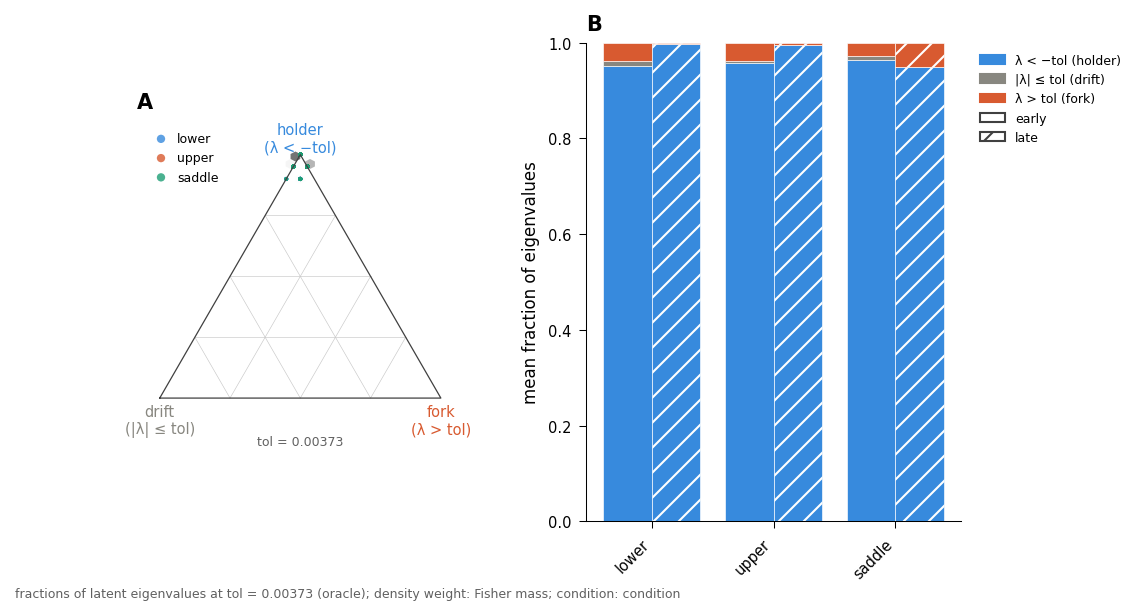

,cluster,condition,n,frac_neg,frac_zero,frac_pos
0,lower,early,130,0.950385,1.115386e-02,0.038462
1,lower,late,298,0.995973,1.510068e-03,0.002517
2,saddle,early,346,0.962861,9.537580e-03,0.027601
3,saddle,late,1,0.950000,1.117587e-08,0.050000
4,upper,early,124,0.956452,6.048397e-03,0.037500
5,upper,late,301,0.994352,1.328905e-03,0.004319


In [16]:
show(P.figure_behaviour_ternary(pf, color_key="cluster", condition_key="condition",
                                conditions=("early", "late"), out=OUT / "C1_ternary"))
P.behaviour_composition(pf, by="cluster", condition_key="condition")

### C2. `figure_behaviour_landscape` — occupancy of operator space

**Question.** Where do cells concentrate in operator space, and is that
structure stronger than a scrambled null?

**Needs.** `obs["lead_re"]` and `obs["spectral_gap"]` (or `"henrici"`);
optionally a null from `opspace.flow_scrambled_null`.

**How to read it.** x = `lead_re` (left = held, right = expanding), y =
spectral gap (how cleanly the leading mode is separated from the next).
Coloured contours = Fisher-weighted density of cells; **grey contours = the
null** (operators refitted on scrambled data). Density that the null also has
is not structure. `subtract=True` draws only the excess over the null. Here
the null collapses to a small blob near (0, 0): scrambled data has no basins
or saddles, so the separated peaks (two holder basins on the left, the fork
ridge on the right) are real structure.

**Watch out.** Use `y="spectral_gap"` for symmetric operators — Henrici
(non-normality) is ~0 for every cell there.

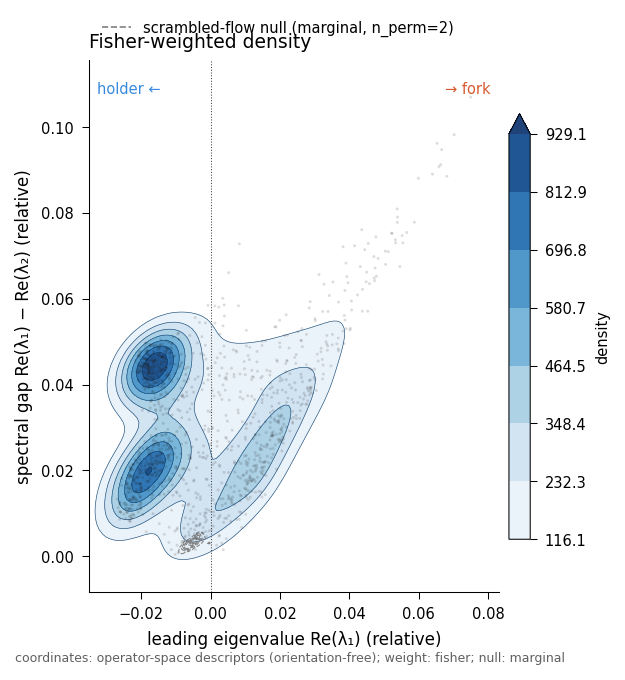

In [17]:
show(P.figure_behaviour_landscape(pf, y="spectral_gap", null=null, out=OUT / "C2_behaviour_landscape"))

### C3. `figure_behaviour_landscape_3d` — depth versus crowding

**Question.** Are the crowded regions of operator space also the deeply held
ones?

**How to read it.** The same floor as C2; bar **height = well stiffness**
(`−mean` of the negative eigenvalues: how strongly the holding directions
pull back), floor contours = density. A tall bar over a sparse floor is a deep
well few cells sit in; a crowded floor under low bars is a shallow well many
cells occupy. Grey ticks = the null's height.

**Watch out.** `height="basin_index"` is just `−x` (a plane) and
`height="energy"` redraws density; the default stiffness is the reading that
adds information.

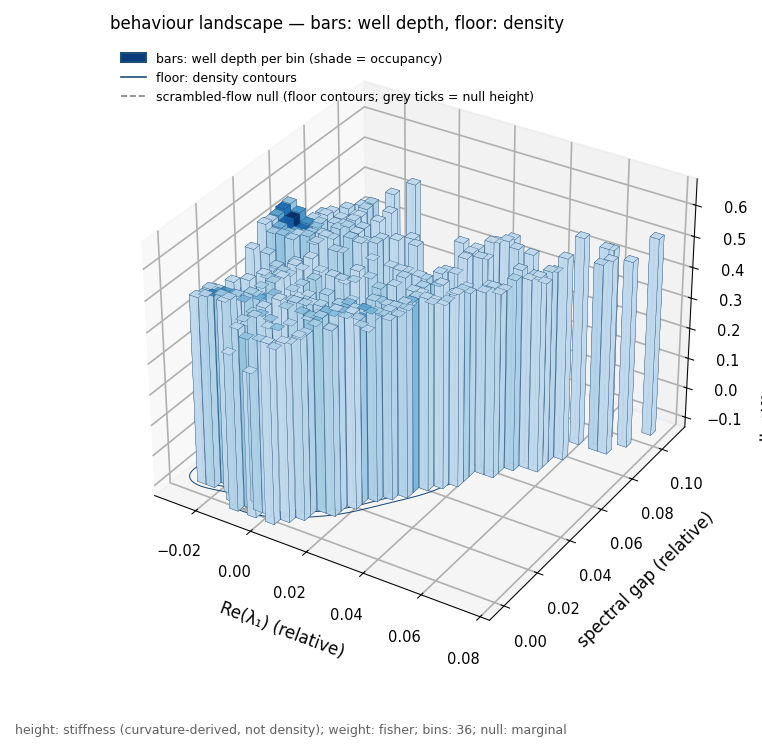

In [18]:
show(P.figure_behaviour_landscape_3d(pf, y="spectral_gap", null=null, out=OUT / "C3_behaviour_landscape_3d"))

### C4. `figure_energy_landscape` — the Waddington picture

**Question.** What does the learned energy `E(z)` look like over the cells?

**Needs.** `opspace.store_energy` (an energy drift); a 2-D floor in `obsm`.

**How to read it.** A surface of `E` over a 2-D floor (here the true 2-D state
of the pitchfork; on real data UMAP or PCA), cells drawn on the floor coloured
by basin class. Valleys = where cells pile up; passes between valleys = likely
transitions.

**Watch out.** On snapshot data `E ≈ −log density`, so valley depth is
*abundance*, not how firmly cells are held — that is C3's job. On a UMAP
floor the surface is a picture of density on the UMAP, not of the latent
space.

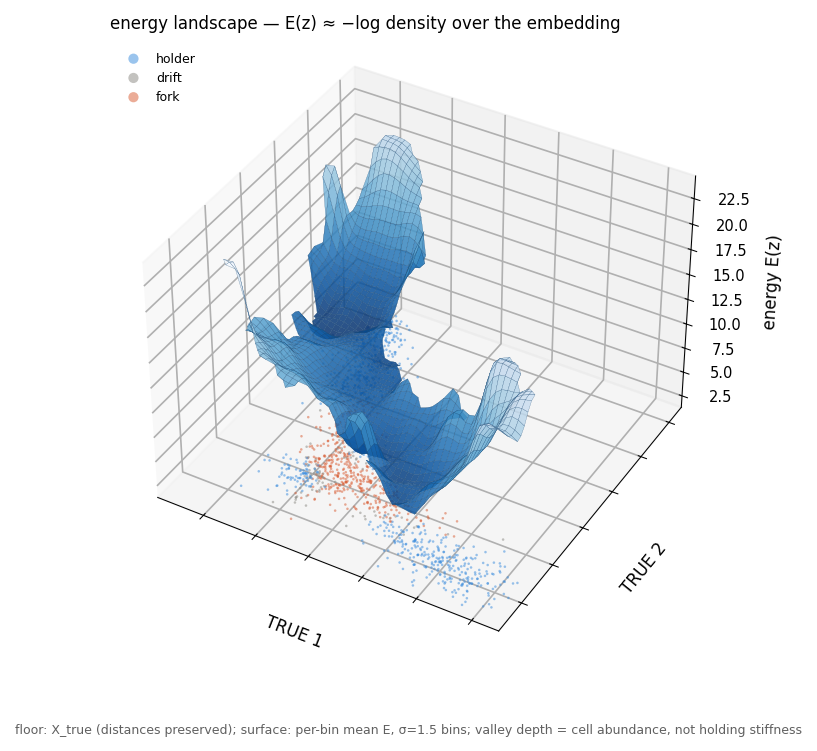

In [19]:
show(P.figure_energy_landscape(pf, use_rep="X_true", out=OUT / "C4_energy_landscape"))

### C5. `figure_motif_matrix` — recurring operator motifs across contexts

**Question.** Which operator shapes (spectral motifs) recur, and in which
contexts (clusters, tissues) are they enriched?

**Needs.** `motifs.fit_motifs` + `motifs.motif_occurrence` (run by
`landscape.analyse(motifs=True)`).

**How to read it.** Rows = motifs (named by sign of the lead eigenvalue and
depth), columns = contexts. A cell is filled with the motif's occupancy where
it is enriched above a shuffled-context null, blank otherwise. The bar at the
right counts enriched contexts per motif. A full row = a universal motif; a
row lit in one block = a context-specific one. With driver similarity
computed, a twin panel shows how similar the motif's genes are across
contexts.

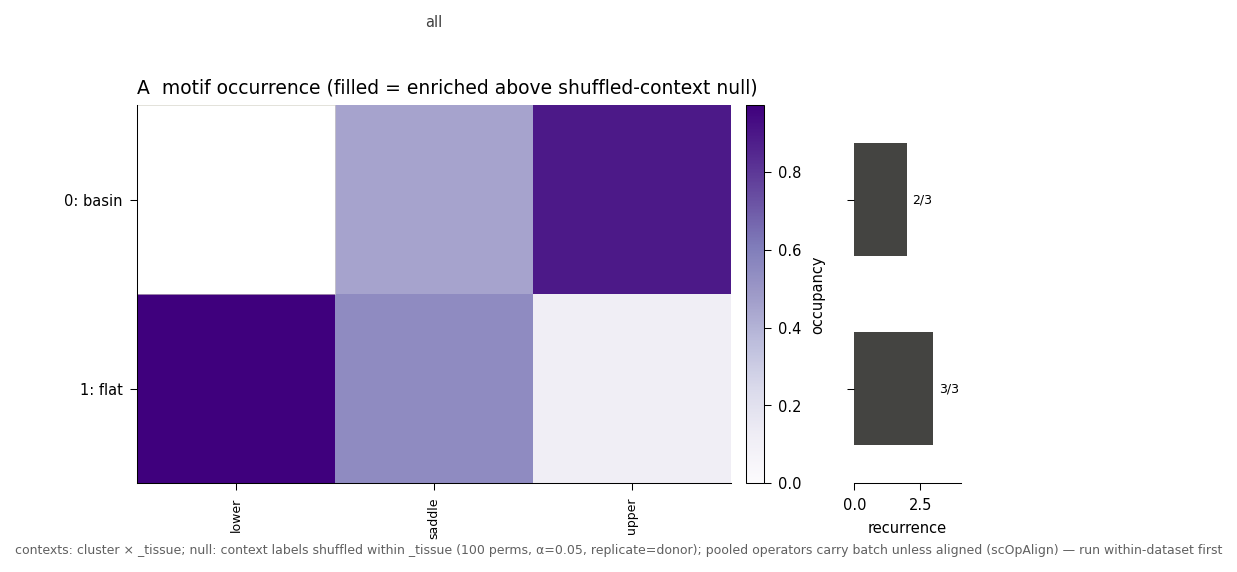

In [20]:
show(P.figure_motif_matrix(pf, out=OUT / "C5_motif_matrix"))

---
## Part D — Perturbation: `figure_perturb_paired`

**Question.** Does the operator predict the response to a knockdown better
than differential expression alone?

**Needs.** The K562 Perturb-seq comparison tables (per-knockdown cosines and
the generic-response decomposition).

**How to read it.**
* **Left** — one point per knockdown: x = cosine between the DE-only
  prediction and the observed response, y = cosine for the operator
  prediction. Points above the `y = x` line are knockdowns the operator
  predicts better; the win fraction is printed.
* **Right** — mean cosine for the **full** observed response and for the
  **residual** after removing the *generic* response every knockdown shares,
  for the operator (orange) and DE-only (blue) predictions. A method that only
  captures the generic response scores on "full" but drops to ~0 on
  "residual"; the operator keeping a positive residual means it predicts the
  knockdown-specific part.

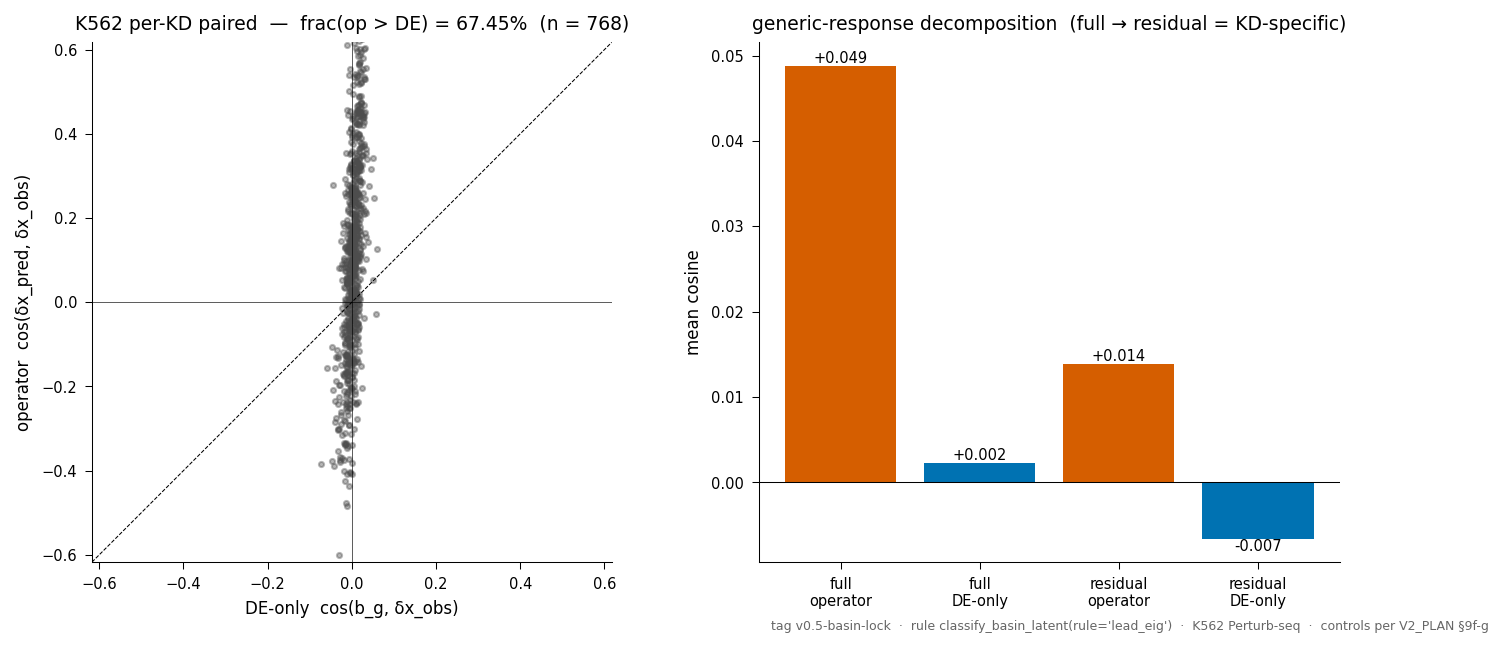

In [21]:
K = REPO / "benchmarks" / "perturbseq_k562"
gen = K / "generic_control_comparison.csv"
show(P.figure_perturb_paired({"per_kd": pd.read_csv(K / "per_knockdown.csv"),
                              "generic_table": pd.read_csv(gen) if gen.exists() else None},
                             out=OUT / "D1_perturb_paired"))

---
## Part E — Aging

### E1. `figure_aging_vectors` — how each cell type's operator changes with age

**Question.** Does aging make a type's basin deeper or shallower, and more or
less anisotropic?

**Needs.** A per-type young/old comparison table with
`young_<x>, old_<x>, young_<y>, old_<y>` columns (here from
`benchmarks/aging/compare_pooled.csv` + the mode labels).

**How to read it.** One panel per tissue; each arrow is one cell type, from
young (hollow dot) to old (arrow head), on log axes: x = overall stiffness
(median `|λ|`, right = stiffer), y = anisotropy (soft-axis curvature over the
median; up = one soft axis dominates more). Colour = the aging mode label.
Each arrow is labelled with the cell type and its stiffness fold change
(old/young). Colour = mode: blue softening, red stiffening, grey mixed — in
this run every type is "mixed", so all arrows are grey. Arrows pointing the
same way across types suggest a shared aging mode.

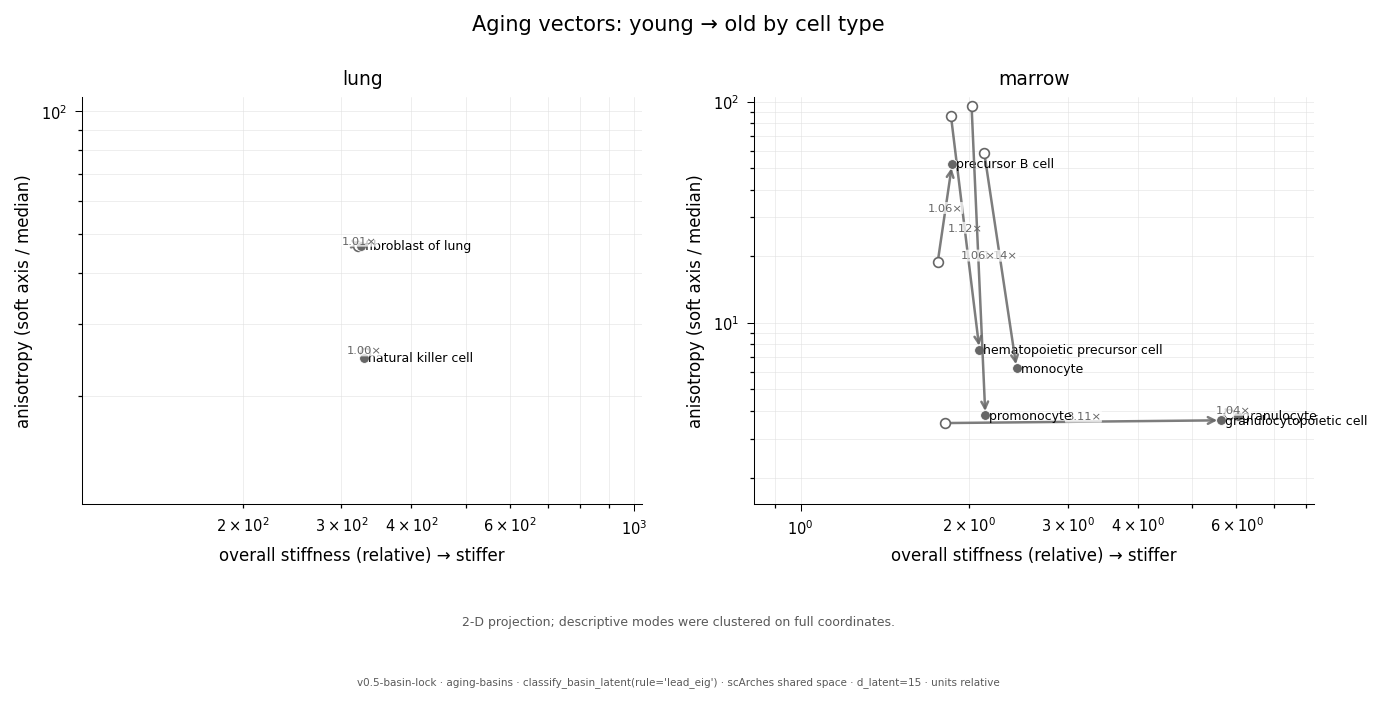

In [22]:
A = REPO / "benchmarks" / "aging"
pooled = pd.read_csv(A / "compare_pooled.csv").merge(
    pd.read_csv(A / "aging_modes.csv"), on=["tissue", "cell_type"], how="left")
vec = pooled.rename(columns={"median_abs_lambda_young": "young_median_abs_lambda",
                             "median_abs_lambda_old": "old_median_abs_lambda",
                             "anisotropy_young": "young_anisotropy",
                             "anisotropy_old": "old_anisotropy", "mode_label": "mode"})
show(P.figure_aging_vectors(vec, out=OUT / "E1_aging_vectors"))

### E2. `figure_energy_transect` — the energy along a type's soft axis

**Question.** Is there an energy barrier between a cell type and its nearest
neighbour type, and where does the old centroid sit on it?

**Needs.** The shared young/old AnnData and the trained energy model for the
tissue (`benchmarks/aging/<tissue>_shared.h5ad`,
`benchmarks/aging/models/<tissue>_shared_drift.pt`). These large inputs are
**not in this checkout**, so the call is shown and the stored rendering is
displayed instead:

```python
fig = P.figure_energy_transect(shared, "fibroblast of lung", neighbour,
                               energy=drift, use_rep="X_scVI_shared",
                               out=OUT / "E2_energy_transect")
```

**How to read it.** x = position along the line from the young centroid of the
type, following its soft (leading) eigendirection, to the neighbour type's
centroid; y = learned energy. The two ends are the floors; the highest strict
local maximum between them is the saddle (barrier). The old centroid is
projected onto the line: if it has moved toward the saddle, aging has pushed
the type toward the barrier.

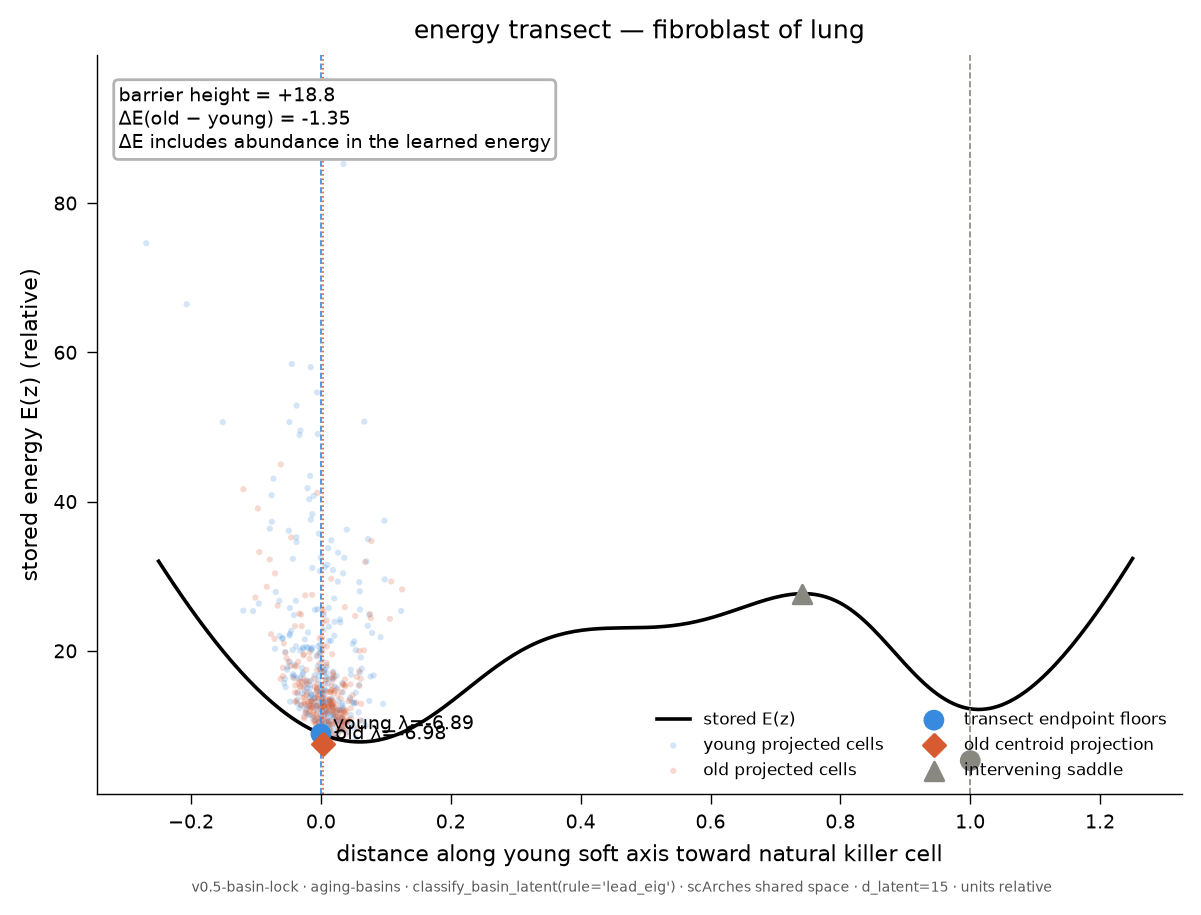

In [23]:
img = REPO / "benchmarks" / "figures" / "aging" / "lung" / "energy_transect_fibroblast_of_lung.png"
display(Image(filename=str(img), width=640)) if img.exists() else print("stored rendering not found:", img)

---
## Part F — Drivers, responders and timing (Paul15)

The figures in Part A show what **moves**. These figures ask which genes **make
others move**. For each archetype the finite-time change operator
`M(t) = Pᵀ(e^{Bt} − I)P` (tangent block `B`, projector `P`) gives:

* **out-influence** of gene *j* = how much a small push on *j* moves the other
  genes at time `t*` (column norm of `M`, self excluded);
* **in-influence** of gene *i* = how much *i* is moved by small pushes on the
  others (row norm).

Influential genes (top 10 % of out + in) are split by **polarity**
`log₂(out/in)` relative to the archetype: **driver** (moves more than it is
moved), **responder** (the reverse), **hub** (both). Genes with no measured
Jacobian column are **unmeasured** — not uninfluential.

`drivers.analyse` runs every analysis in order. Here: TRRUST (mouse) as the
reference network and the Paul15 branches (root 7MEP; erythroid, monocyte,
neutrophil) for the branch-aware timing. Permutation counts are reduced to 500
to keep the notebook quick; the stored benchmark uses 2,000.

In [24]:
ref = D.load_reference(REPO / "benchmarks" / "data" / "trrust" / "trrust_rawdata.mouse.tsv")
BR = {"erythroid": ["6Ery", "5Ery", "4Ery", "3Ery", "2Ery", "1Ery"],
      "monocyte": ["9GMP", "10GMP", "14Mo", "15Mo"],
      "neutrophil": ["9GMP", "10GMP", "16Neu", "17Neu"]}
t = time.time()
res = D.analyse(paul, ref_network=ref, time_key="pseudotime", branches=BR,
                cluster_key="paul15_clusters", root=["7MEP"], n_perm=500, seed=SEED)
print(f"drivers.analyse in {time.time() - t:.0f}s; tables: {sorted(res)}")
res["roles"][["archetype", "behaviour", "n_cells", "t_star", "n_driver", "n_hub", "n_responder",
              "n_unmeasured", "top_drivers", "top_responders"]]

drivers.analyse in 12s; tables: ['branch_lags', 'branch_members_lags', 'branch_members_onsets', 'branch_members_overall', 'branch_members_pooled', 'branch_members_summary', 'branch_onsets', 'branch_overall', 'branch_pooled', 'branch_summary', 'edges', 'influence', 'key_genes', 'reference_edges', 'reference_per_tf', 'reference_summary', 'roles', 'timing_edges', 'timing_onsets', 'timing_summary']


,archetype,behaviour,n_cells,t_star,n_driver,n_hub,n_responder,n_unmeasured,top_drivers,top_responders
0,0,fork,411,1.440899,2,25,0,39,"Crip1, Psmb8",
1,1,fork,323,1.902704,1,21,3,58,Mt1,"Malat1, Gata2, Itga2b"
2,2,fork,601,3.667790,1,25,0,50,Irf1,
3,3,fork,702,3.419982,0,21,4,59,,"Apoe, Nrgn, Irf8, Emb"
4,4,fork,506,2.452690,0,23,1,61,,Ptprcap
5,5,fork,561,1.984469,1,23,1,51,Iqgap1,Malat1
6,6,fork,949,10.174256,6,13,0,114,"Nrgn, Car1, Rhd, Mrpl52, Glrx5",
7,7,fork,372,2.142464,3,23,0,47,"Zfpm1, Vamp5, Gm2a",


### F1. `figure_influence_network` — drivers, responders and their edges

**Question.** Which genes drive each archetype, which respond, and how are
they wired at the archetype's own time scale `t*`?

**Needs.** `drivers.influence` (run by `analyse`); optional reference network.

**How to read it** (one row per archetype; two shown here, all in the saved file):
* **(a) map** — in-influence (x) vs out-influence (y), log scale. The dotted
  curve is the influential cut (below it: passengers); the dashed diagonals
  are the polarity cuts: above the upper one = **driver**, below the lower one
  = **responder**, between = **hub**. The count of unmeasured genes is printed.
* **(b) influence over time** — each top driver's share of total
  out-influence across `t` (log scale; dotted line = `t*`). Shares remove the
  common growth `e^{λt}`, so crossing lines mean the ranking changes with time
  (non-normal transients). Flat lines = the ranking is the same at every time.
* **(c) network at `t*`** — columns: drivers → hubs → responders/other.
  Arrow `j → i` = the change in *i* per push on *j*: red = activating,
  blue = repressing, width = size. With a reference network, solid = also in
  the reference, dashed = dynamics only, dotted grey = reference only.

**Watch out.** Edges are *predicted effects of small changes under the fitted
`J`*, not proven regulation. The title gives `t*` and the rule that chose it
(transient-gain peak for stable blocks, else `1/|Re λ₁|`).

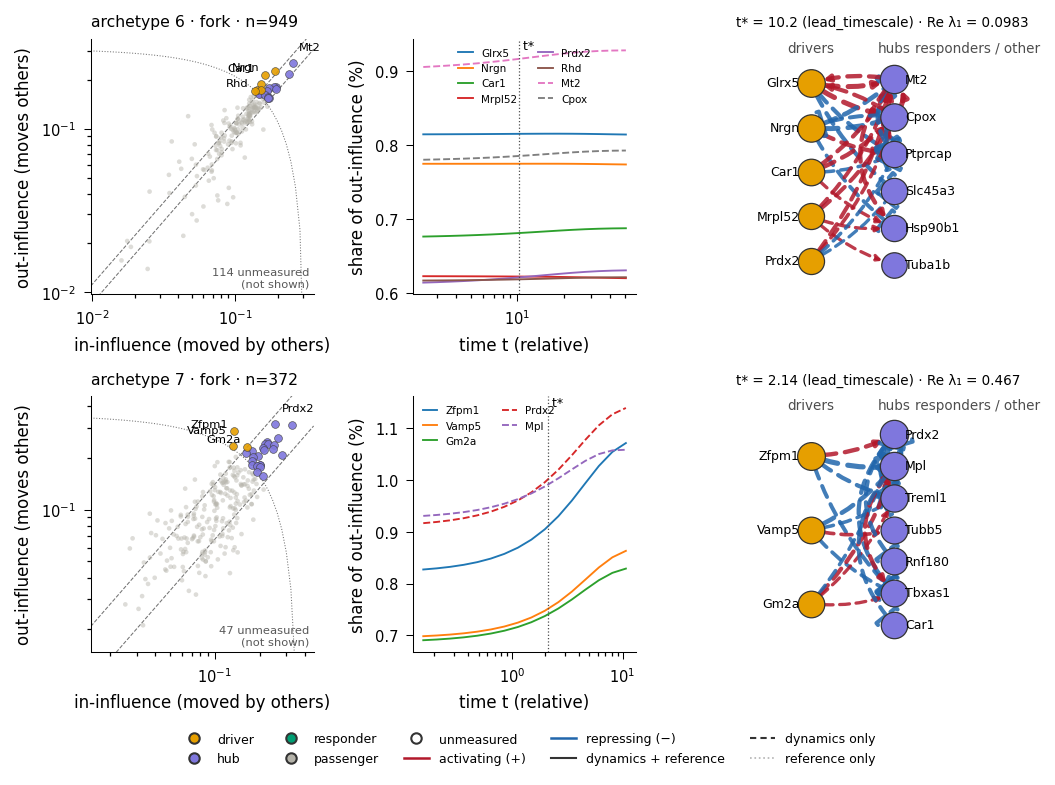

[PosixPath('/Users/terooatt/Documents/scJDO2/benchmarks/v2/tutorial_07/F1_influence_network_all.pdf'),
 PosixPath('/Users/terooatt/Documents/scJDO2/benchmarks/v2/tutorial_07/F1_influence_network_all.png')]

In [25]:
show_ids = [6, 7]
show(D.plot_network(paul, archetype_ids=show_ids, ref_network=ref, out=OUT / "F1_influence_network"))
P.save_figure(D.plot_network(paul, ref_network=ref), OUT / "F1_influence_network_all")

### F2. `figure_reference_auroc` — do the edges recover known regulation?

**Question.** For TFs with known targets, does the Jacobian rank those targets
above other genes — better than co-expression does?

**Needs.** `drivers.reference_check` (run by `analyse` with `ref_network`).

**How to read it.**
* **(a)** per archetype: mean AUROC across reference TFs for the Jacobian
  (amber, ranking by `|M[i, TF](t*)|`) and for `|Spearman|` co-expression
  (grey). 0.5 = chance. The grey tick is the 95th percentile of a random-target
  null; `*` p < 0.05, `**` survives Bonferroni across archetypes.
* **(b)** per TF: Jacobian AUROC vs co-expression AUROC (mean over
  archetypes); above the diagonal = the Jacobian does better. Marker size =
  number of reference targets in the gene set.

**Watch out.** Only reference edges whose TF *and* target are in the gene set
count — here a few dozen — so the test has little power, and the archetypes
share those edges (their p-values are not independent).

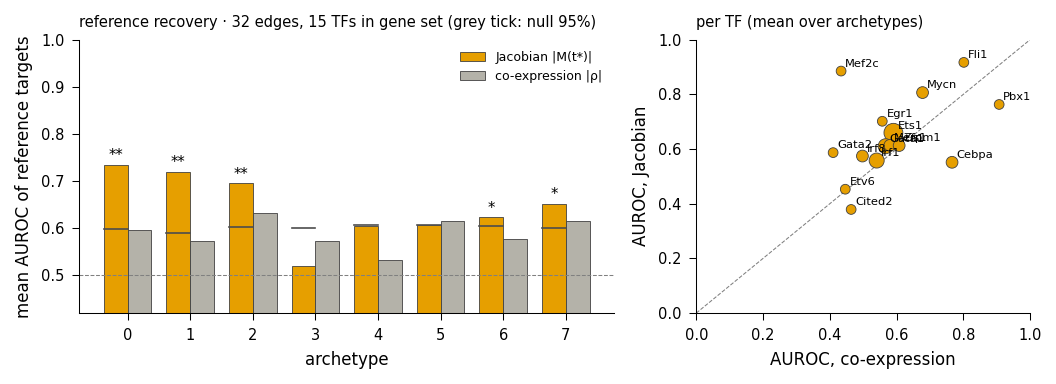

,archetype,n_edges,mean_auroc_jacobian,p_jacobian,mean_auroc_coexpr,sign_agreement,base_rate_M_pos
0,0,32,0.734,0.002,0.597,0.727,0.661
1,1,32,0.720,0.004,0.574,0.727,0.710
2,2,32,0.695,0.002,0.631,0.818,0.702
3,3,32,0.521,0.407,0.574,0.773,0.699
4,4,32,0.605,0.054,0.533,0.818,0.690
5,5,32,0.606,0.054,0.614,0.818,0.693
6,6,32,0.623,0.024,0.577,0.818,0.757
7,7,32,0.651,0.014,0.616,0.773,0.634


In [26]:
show(D.plot_reference({"summary": res["reference_summary"], "per_tf": res["reference_per_tf"]},
                      out=OUT / "F2_reference_auroc"))
res["reference_summary"][["archetype", "n_edges", "mean_auroc_jacobian", "p_jacobian",
                          "mean_auroc_coexpr", "sign_agreement", "base_rate_M_pos"]].round(3)

### F3. `figure_expression_cascade` — do drivers change first along pseudotime?

**Question.** Within each archetype's cells, do the drivers' expression
changes precede the responders' along an existing pseudotime?

**Needs.** `drivers.timing` (run by `analyse`). No new pseudotime is built:
`obs["pseudotime"]` is used as is.

**How to read it** (one row per archetype; two shown):
* **(a) heatmap** — rows = genes grouped by role (colour strip: driver,
  hub, responder) and sorted by **onset** (black tick: where the gene's
  smoothed, 0–1 scaled expression crosses halfway); `↓` marks falling genes.
* **(b) role curves** — median scaled curve per role with its IQR band
  (falling genes flipped so all read low → high); dotted lines = median onset
  per role. Drivers first ⇒ the amber curve rises left of the green one.
* **(c) onsets** — each gene's onset by role; the title reports the role
  test (drivers earlier, Mann–Whitney) and the edge test (fraction of
  driver → target edges whose source changes first, vs random gene pairs).

**Watch out.** If the drift was fitted with this same pseudotime (Paul15 uses
it as a velocity prior), passing is a *consistency* check, not independent
proof. In a fork archetype, averaging both fates can cancel the driver's
signal — that is what F4 fixes.

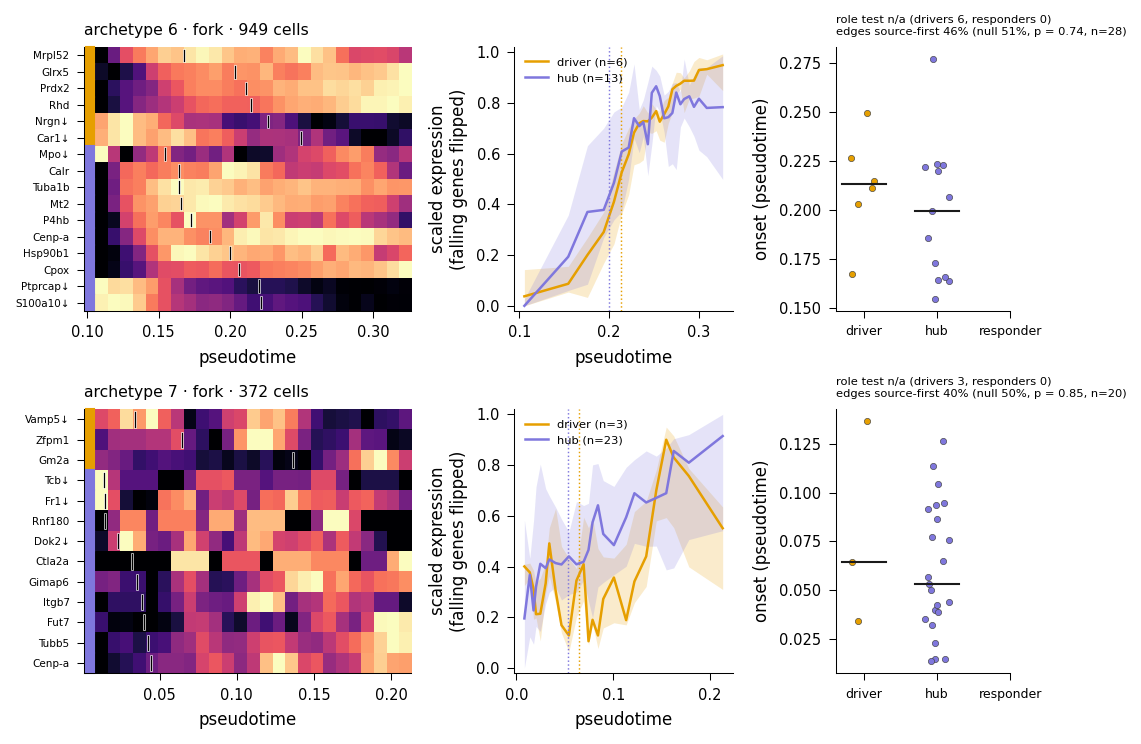

,archetype,n_driver,n_responder,p_driver_earlier,edge_n_edges,edge_frac_source_first,edge_null_frac,edge_p_perm
0,0,2,0,NaN,16,0.500,0.498,0.589
1,1,1,3,NaN,12,0.417,0.497,0.796
2,2,1,0,NaN,12,0.583,0.489,0.363
3,3,0,4,NaN,8,0.500,0.507,0.659
4,4,0,1,NaN,8,0.875,0.494,0.028
5,5,1,1,NaN,12,0.417,0.504,0.800
6,6,6,0,NaN,28,0.464,0.505,0.743
7,7,3,0,NaN,20,0.400,0.496,0.848


In [27]:
show(D.plot_cascade(paul, archetype_ids=show_ids, out=OUT / "F3_expression_cascade"))
res["timing_summary"][["archetype", "n_driver", "n_responder", "p_driver_earlier",
                       "edge_n_edges", "edge_frac_source_first", "edge_null_frac", "edge_p_perm"]].round(3)

### F4. `figure_branch_timing` — the same test along each fate branch

**Question.** Along each lineage separately, do drivers change before their
targets?

**Needs.** `drivers.branch_timing` (run by `analyse` with `branches`,
`cluster_key`, `root`). Two variants: all cells on each branch path
(`branch_*`), or only the archetype's member cells on it (`branch_members_*`).

**How to read it.**
* **(a) matrix** — rows = archetypes, columns = branches (+ pooled). Each
  cell = fraction of driver → target edges whose source changes first: 0.5 =
  chance, orange = driver first, purple = target first; `n` = edges tested,
  `*` p < 0.05 against random pairs. The title gives the overall fraction and
  its null.
* **(b) lags** — `onset(target) − onset(source)` for every edge, per branch;
  above the dashed zero line = the driver changes first.

**Watch out.** Expect about 1 in 20 cells to be "significant" by chance; look
for a consistent pattern (e.g. an erythroid archetype along the erythroid
branch), not isolated stars.

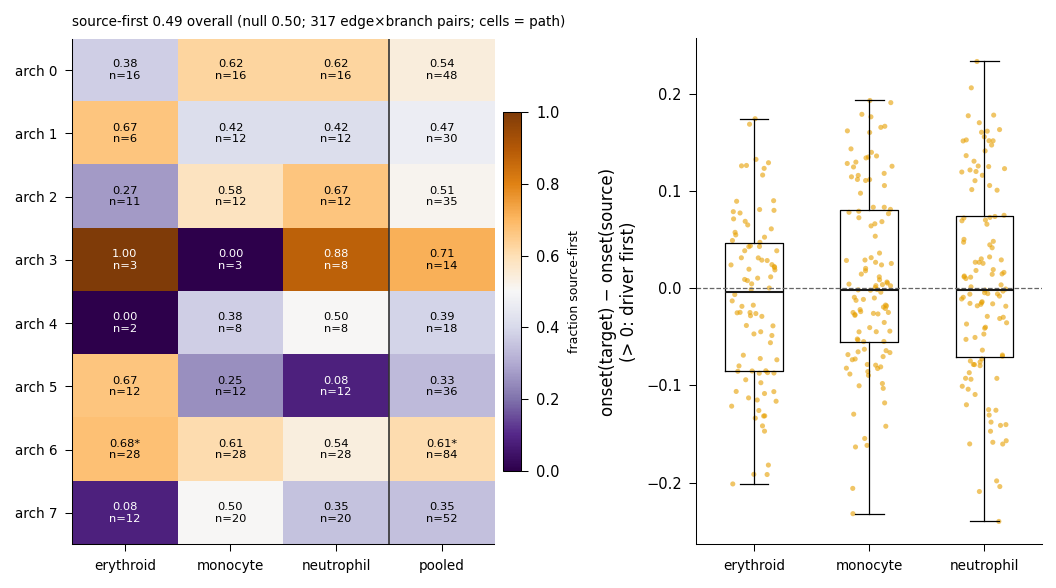

,n_pairs,frac_source_first,null_frac,n_archetype_branch_p05,n_archetype_branch_tested,cells
0,317,0.492114,0.499494,1,24,path


In [28]:
br = {k: res[f"branch_{k}"] for k in ("summary", "pooled", "lags", "overall")}
show(D.plot_branch_timing(br, out=OUT / "F4_branch_timing"))
res["branch_overall"]

### F5. `figure_network_expression` — one archetype, state by state (optional QC)

**Question.** For one archetype's network, does each driver switch on before
its responders as cells move from one state to the next?

**Needs.** `drivers.network_expression(adata, k, cluster_key, states=...)`.
Pass `states` in trajectory order along **one** branch; the default order
(clusters holding ≥ 5 % of the archetype's cells, sorted by median
pseudotime) is only a trajectory for single-lineage archetypes.

**How to read it.**
* **left — dot heatmap**, one block per driver (driver row in bold, then its
  targets). Colour = mean expression scaled 0–1 per gene across states; dot
  size = fraction of cells expressing; **▼ = on-state** (where the scaled
  mean crosses 0.5); `↓` = falling gene; colour strip = role.
* **right — one panel per driver**: the driver (thick black) and its targets
  (thin, coloured by role) across states; dotted line = the driver's on-state.
  The title counts how many targets switch on after the driver.

**Watch out.** With few states, "first" can rest on a fraction of a state;
read the curves, not just the counts.

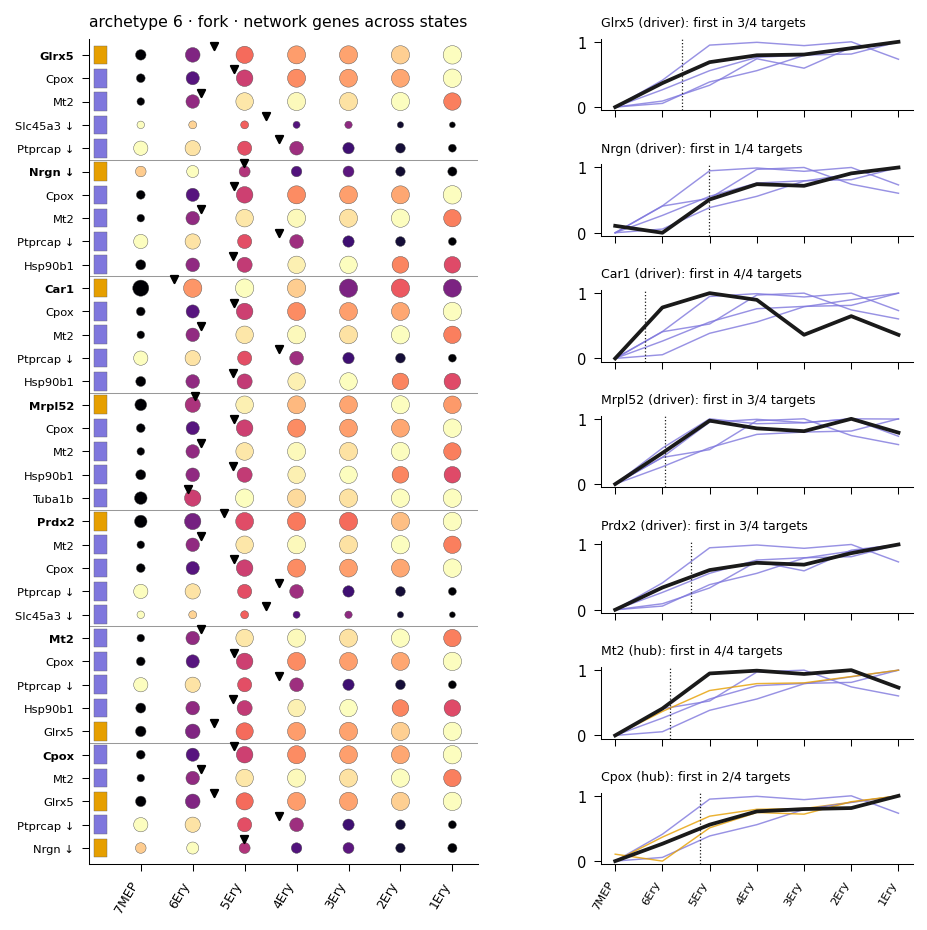

,source,n_targets,n_driver_first
0,Car1,4,4
1,Cpox,4,2
2,Glrx5,4,3
3,Mrpl52,4,3
4,Mt2,4,4
5,Nrgn,4,1
6,Prdx2,4,3


In [29]:
ery = ["7MEP", "6Ery", "5Ery", "4Ery", "3Ery", "2Ery", "1Ery"]
ne = D.network_expression(paul, 6, "paul15_clusters", states=ery)
show(D.plot_network_expression(paul, 6, out=OUT / "F5_network_expression_arch6"))
ne["summary"]

---
## Rendering everything at once

The one-call APIs render their whole family into a folder and return the
paths:

```python
landscape.figures(adata, out_dir, color_key="cluster", condition_key="condition", null=null)
D.figures(adata, out_dir, ref_network=ref, results=res, cluster_key="paul15_clusters",
          states={6: ery})
```

## Which figure for which question

| Question | Figure |
|---|---|
| Where are basins, forks, oscillators on my cells? | `figure_operator_space` (A1), `figure_ledger_map` (B3) |
| What kinds of operator recur? | `figure_archetype_sheet` (A2), `figure_motif_matrix` (C5) |
| How well is the Jacobian measured? | `figure_ledger_summary` (A4) |
| How many directions hold / free each type? | `figure_spectrum_ladder` (B1), `figure_behaviour_ternary` (C1) |
| Along which axis can a type move? | `figure_soft_axis_map` (B2), `figure_energy_transect` (E2) |
| Which types are deeply held? | `figure_basin_index` (B4), `figure_behaviour_landscape_3d` (C3) |
| Is the learned operator right? | `figure_oracle_agreement` (B5), `figure_perturb_paired` (D1), `figure_reference_auroc` (F2) |
| Is there structure beyond a null? | `figure_behaviour_landscape` (C2) |
| What does aging change? | `figure_aging_vectors` (E1), `figure_soft_axis_map(groups=…)` |
| Which genes drive, which respond? | `figure_influence_network` (F1), `plot_drivers` (A3) |
| Do drivers change first? | `figure_expression_cascade` (F3), `figure_branch_timing` (F4), `figure_network_expression` (F5) |

## Common pitfalls

1. **Relative units.** Eigenvalues and `t` are in the operator's own time
   unit unless the clock is calibrated; compare signs and ratios, not values,
   across datasets.
2. **Snapshot vs measured flow.** A symmetric snapshot operator reads the
   *density landscape* (basins and ridges). Dynamics claims (oscillation,
   drivers vs responders) need a non-symmetric operator from measured flow.
3. **Unmeasured ≠ unimportant.** Zero-Fisher genes are flagged everywhere;
   a capped TF can be the real driver.
4. **Nulls first.** Read density, enrichment and timing against their nulls.

In [30]:
print(f"notebook ran in {time.time() - T0:.0f}s; figures written to {OUT}")
sorted(p.name for p in OUT.glob("*.png"))

notebook ran in 120s; figures written to /Users/terooatt/Documents/scJDO2/benchmarks/v2/tutorial_07


['A1_operator_space.png',
 'A2_archetype_sheet.png',
 'A3_plot_drivers.png',
 'A4_ledger_summary.png',
 'A5_v1_vs_v2.png',
 'B1_spectrum_ladder.png',
 'B2_soft_axis_map.png',
 'B3_ledger_map.png',
 'B4_basin_index.png',
 'B5_oracle_agreement.png',
 'B6_operator_space_snapshot.png',
 'C1_ternary.png',
 'C2_behaviour_landscape.png',
 'C3_behaviour_landscape_3d.png',
 'C4_energy_landscape.png',
 'C5_motif_matrix.png',
 'D1_perturb_paired.png',
 'E1_aging_vectors.png',
 'F1_influence_network.png',
 'F1_influence_network_all.png',
 'F2_reference_auroc.png',
 'F3_expression_cascade.png',
 'F4_branch_timing.png',
 'F5_network_expression_arch6.png']